In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Scalar values

In [2]:
# No of grid poins
N = 11

# Domain size
L = 1

# Corresponding grid spacing
h = np.float64(L/(N-1)) 

# Thermal conductivity
k = 1.0

# cross section area
A = 0.001

# Iteration number
iterations = 0

# temprature field initializing

In [3]:
# initializing temprature field
T = np.zeros(N)
T[N-1] = 1.

# Initializing iterated temprature
T_new = np.zeros(N)
T_new[N-1] = 1.

# error related variables
epsilon = 1.E-8
numerical_error = 1

# Computation neumann

In [4]:
while numerical_error > epsilon:
    # Computing for all interior points
    for i in range(0, N-1):
        a_e = np.float64(k*A/h)
        a_w = np.float64(k*A/h)

        # generalized equation for all points
        a_p = a_e + a_w
        T_new[i] = (a_e*T[i+1] + a_w*T[i-1])/a_p
           
    # Resetting the numerical error and recalculate
    numerical_error = 0
    for i in range(1, N-1):
        numerical_error = numerical_error + abs(T[i]-T_new[i])
        
    # Iteration advancement and reassignment
    iterations = iterations + 1
    T = T_new.copy()

In [5]:
print("The number of iterations is: ", iterations)

The number of iterations is:  421


In [6]:
print("The final numerical error value is: ", numerical_error)

The final numerical error value is:  9.803435063737709e-09


In [7]:
print("Final temperature field is: ", T)

Final temperature field is:  [0.99999999 0.99999998 0.99999997 0.99999997 0.99999997 0.99999997
 0.99999997 0.99999997 0.99999998 0.99999999 1.        ]


# Plotting the results

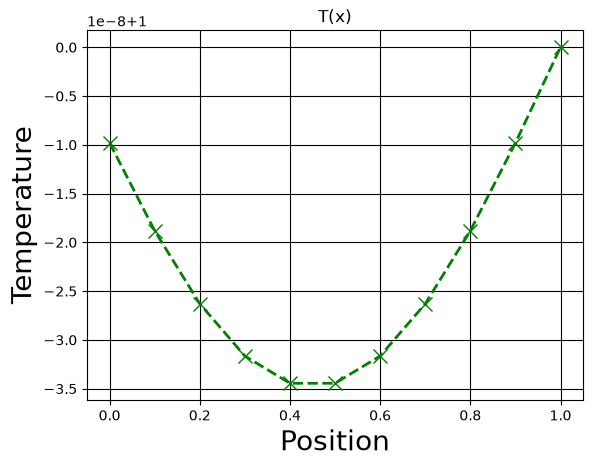

In [8]:
# Defining the position vector fromindices
x_dom = np.arange(N)*h

# Plotting the variation with customization
plt.plot(x_dom, T, 'gx--', linewidth=2, markersize=10)

#Displaying gridlines
plt.grid(True, color='k')

# Labelling and providing a title to the plot
plt.xlabel("Position", size=20)
plt.ylabel("Temperature", size=20)
plt.title("T(x)")

# Showing the plot on screen
plt.show()